# Forced Duffing Oscillator Identification

This notebook identifies forced Duffing dynamics from one simulated trajectory with a second-order formulation.

**System:** $u'' + \delta u' + \alpha u + \beta u^3 = \gamma \cos(\omega t)$

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from wias import (
    build_weak_system_second_order,
    make_test_basis,
    CPQR_solver,
)

## Define the library of candidate functions and ground truth coefficients

In [2]:
def duffing_forcing(t):
    """Periodic forcing function for Duffing oscillator."""
    return gamma * np.cos(omega * t)

def duffing_library(states):
    """
    Polynomial library up to degree 3 for the state-dependent terms.
    For second-order formulation: u'' + terms = forcing(t)
    """
    u_val = states[:, 0]
    v_val = states[:, 1]  # v = u'
    
    columns = np.column_stack([
        np.ones_like(u_val),
        u_val,
        v_val,
        u_val**2,
        u_val * v_val,
        v_val**2,
        u_val**3,
        u_val**2 * v_val,
        u_val * v_val**2,
        v_val**3,
    ])
    names = ["1", "u", "v", "u^2", "uv", "v^2", "u^3", "u^2v", "uv^2", "v^3"]
    return columns, names

# System parameters
alpha = 1.0      # Restoring force coefficient
beta = 5.0       # Cubic nonlinearity
delta = 0.02     # Damping
gamma = 8.0      # Forcing amplitude
omega = 0.5      # Forcing frequency

## Define system parameters and generate trajectory.

Initial condition (random position, zero velocity): [0.49671415 0.        ]
Time span: 0.00 to 100.00
Samples per trajectory: 1000001
System: u'' + 0.02*u' + 1.0*u + 5.0*u^3 = 8.0*cos(0.5*t)


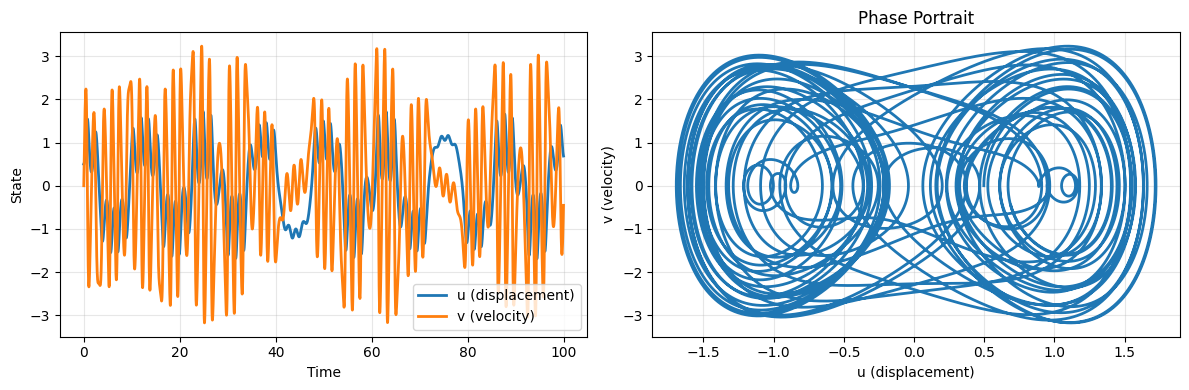

In [8]:
# Time discretization
time = np.linspace(0.0, 100.0, int(1e6)+1)

# Initial condition: random position, zero velocity
np.random.seed(42)  # for reproducibility
initial_condition = np.array([np.random.randn(), 0.0])

# Ground truth ODE for simulation
def duffing_rhs_true(t, state):
    """RHS with time-dependent forcing for ground truth trajectory."""
    u, v = state
    du_dt = v
    dv_dt = -delta * v - alpha * u - beta * u**3 + gamma * np.cos(omega * t)
    return np.array([du_dt, dv_dt])

# Generate trajectory
solution = solve_ivp(
    duffing_rhs_true,
    (float(time[0]), float(time[-1])),
    np.asarray(initial_condition, dtype=float),
    t_eval=time,
    method="RK45",
    rtol=1e-10,
    atol=1e-12,
)
trajectory = solution.y.T

print(f"Initial condition (random position, zero velocity): {initial_condition}")
print(f"Time span: {time[0]:.2f} to {time[-1]:.2f}")
print(f"Samples per trajectory: {len(time)}")
print(f"System: u'' + {delta}*u' + {alpha}*u + {beta}*u^3 = {gamma}*cos({omega}*t)")

# Plot trajectory
fig = plt.figure(figsize=(12, 4))

ax1 = fig.add_subplot(121)
ax1.plot(time, trajectory[:, 0], label="u (displacement)", linewidth=2)
ax1.plot(time, trajectory[:, 1], label="v (velocity)", linewidth=2)
ax1.set_xlabel("Time")
ax1.set_ylabel("State")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(122)
ax2.plot(trajectory[:, 0], trajectory[:, 1], linewidth=2)
ax2.set_xlabel("u (displacement)")
ax2.set_ylabel("v (velocity)")
ax2.grid(True, alpha=0.3)
ax2.set_title("Phase Portrait")

plt.tight_layout()
plt.show()

## Build Weak-Form System (Second-Order Formulation)

The second-order formulation treats u'' as an unknown and uses integration by parts:
$$\int u'' \phi_j \, dt = -\int u' \phi_j' \, dt$$

In [9]:
# Create test basis
test_basis = make_test_basis(time, num_basis=50)
print(f"Created {len(test_basis)} test functions")

# Get library names
lib_vals, alg_lib_names = duffing_library(trajectory)
names = ["u''"] + list(alg_lib_names)  # Full names including u''
print(f"\nLibrary size: {len(alg_lib_names)} algebraic terms + 1 second-order term = {len(names)} total")
print(f"Library terms: {names}\n")

Created 50 test functions

Library size: 10 algebraic terms + 1 second-order term = 11 total
Library terms: ["u''", '1', 'u', 'v', 'u^2', 'uv', 'v^2', 'u^3', 'u^2v', 'uv^2', 'v^3']



## Solve for Coefficients

Build and solve the weak system with second-order formulation.

In [10]:
# Build weak system (second-order formulation)
A, b = build_weak_system_second_order(
    [trajectory],
    time,
    test_basis,
    duffing_library,
    duffing_forcing,
)

print(f"System shape: {A.shape}")

# True coefficients for weak system reference:
# theta_u''*u'' + sum_j theta_j*phi_j(u,v) = gamma*cos(omega*t)
true_coefficients = np.array([
    1.0,         # u'' coefficient
    0.0,         # 1
    alpha,       # u
    delta,       # v (= u')
    0.0,         # u^2
    0.0,         # uv
    0.0,         # v^2
    beta,        # u^3
    0.0,         # u^2v
    0.0,         # uv^2
    0.0,         # v^3
])

# Solve reduced system
theta = CPQR_solver(A, b)

# Normalize by theta_{u''} to get u'' = ...
theta_udd = theta[0]
print(f"theta_{{u''}} = {theta_udd:.6f}")
if abs(theta_udd) < 1e-6:
    raise ValueError("Singular system: theta_{u''} ~ 0")

coeffs_normalized = -theta[1:] / theta_udd
forcing_coeff = gamma / theta_udd

# True normalized coefficients for: u'' = -delta*v - alpha*u - beta*u^3 + gamma*cos(omega*t)
true_coeffs_normalized = -true_coefficients[1:] / true_coefficients[0]

print(f"\nNormalized coefficients (u'' = sum_k coeff_k * lib_k + {forcing_coeff:.6f}*cos({omega}*t)):\n")
for name, coeff, true_c in zip(alg_lib_names, coeffs_normalized, true_coeffs_normalized):
    print(f"  {name:6s}: {coeff:10.6f} (true {true_c:10.6f}, error {coeff - true_c:.3e})")
print(f"\nForcing coefficient: {forcing_coeff:10.6f} (true {gamma:10.6f}, error {forcing_coeff - gamma:.3e})")


System shape: (50, 11)
theta_{u''} = 1.000000

Normalized coefficients (u'' = sum_k coeff_k * lib_k + 8.000000*cos(0.5*t)):

  1     :   0.000000 (true  -0.000000, error 2.956e-12)
  u     :  -1.000000 (true  -1.000000, error 5.149e-11)
  v     :  -0.020000 (true  -0.020000, error 4.038e-11)
  u^2   :  -0.000000 (true  -0.000000, error -1.734e-12)
  uv    :   0.000000 (true  -0.000000, error 2.834e-12)
  v^2   :  -0.000000 (true  -0.000000, error -8.717e-13)
  u^3   :  -5.000000 (true  -5.000000, error -1.009e-10)
  u^2v  :  -0.000000 (true  -0.000000, error -9.982e-11)
  uv^2  :   0.000000 (true  -0.000000, error 1.922e-11)
  v^3   :   0.000000 (true  -0.000000, error 4.915e-12)

Forcing coefficient:   8.000000 (true   8.000000, error 1.051e-10)


## Results

Compare ground truth vs recovered dynamics.

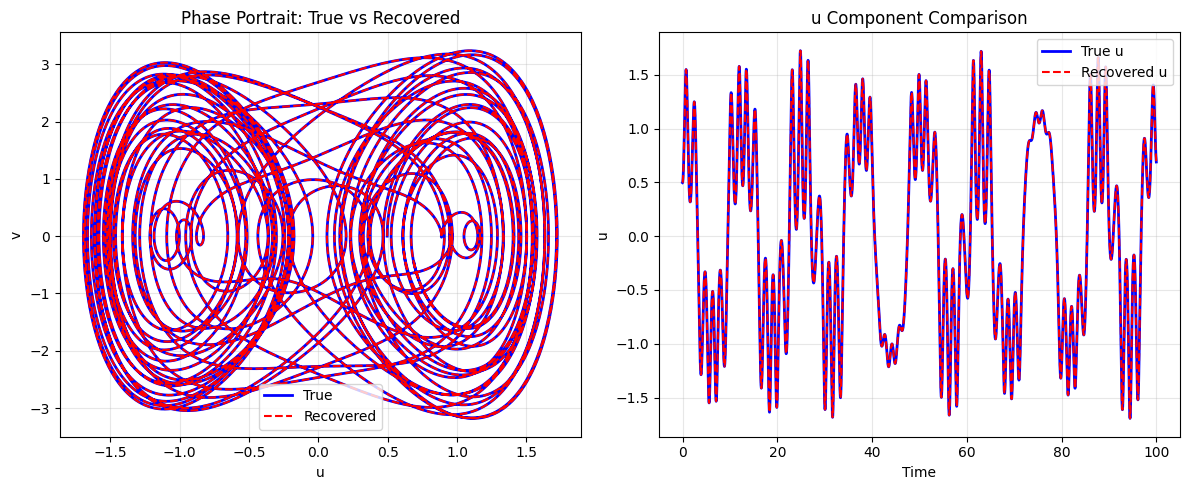

In [11]:
# Function to extract and integrate recovered system
def duffing_feature_vector(state):
    """Build the polynomial library vector at one state."""
    u_val, v_val = state
    return np.array([
        1.0,
        u_val,
        v_val,
        u_val**2,
        u_val * v_val,
        v_val**2,
        u_val**3,
        u_val**2 * v_val,
        u_val * v_val**2,
        v_val**3,
    ])

def duffing_rhs_recovered(t, state):
    """RHS using recovered coefficients and forcing."""
    u, v = state
    du_dt = v
    dv_dt = coeffs_normalized @ duffing_feature_vector(state) + forcing_coeff * np.cos(omega * t)
    return np.array([du_dt, dv_dt])

# Integrate recovered system
recovered_solution = solve_ivp(
    duffing_rhs_recovered,
    (float(time[0]), float(time[-1])),
    np.asarray(initial_condition, dtype=float),
    t_eval=time,
    method="DOP853",
    rtol=1e-10,
    atol=1e-12,
)
recovered_trajectory = recovered_solution.y.T

# Plot original vs recovered trajectories
fig = plt.figure(figsize=(12, 5))

# Phase portrait comparison
ax1 = fig.add_subplot(121)
ax1.plot(trajectory[:, 0], trajectory[:, 1], 
         color="blue", label="True", linewidth=2)
ax1.plot(recovered_trajectory[:, 0], recovered_trajectory[:, 1], 
         color="red", linestyle="--", label="Recovered", linewidth=1.5)
ax1.set_xlabel("u")
ax1.set_ylabel("v")
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_title("Phase Portrait: True vs Recovered")

# Time series comparison
ax2 = fig.add_subplot(122)
ax2.plot(time, trajectory[:, 0], color="blue", label="True u", linewidth=2)
ax2.plot(time, recovered_trajectory[:, 0], color="red", linestyle="--", label="Recovered u", linewidth=1.5)
ax2.set_xlabel("Time")
ax2.set_ylabel("u")
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_title("u Component Comparison")

plt.tight_layout()
plt.show()